In [18]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [19]:
from skimage.feature import blob_log
from scipy.ndimage import maximum_filter

In [20]:
#Load the reduced resolution image
im=cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\the_berry_farms_sunflower_field.jpeg',cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError("Couldn't load the sunflower image.")
#Convert BGR to RGB and grayscale
im_rgb=cv.cvtColor(im,cv.COLOR_BGR2RGB)
gray=cv.cvtColor(im,cv.COLOR_BGR2GRAY)
gray=gray.astype(np.float32)/255.0

In [21]:
sigmas=np.geomspace(0.01,11.0,100)    #sigma values to investigate
scale_space=[]  
for sigma in sigmas:
    blurred=cv.GaussianBlur(gray,(0,0),sigmaX=float(sigma),sigmaY=float(sigma))
    laplacian=cv.Laplacian(blurred,cv.CV_32F,ksize=1)
    normalized_log=(sigma**2)*laplacian
    output=normalized_log**2
    scale_space.append(output)
scale_space = np.stack(scale_space, axis=0)
#print(scale_space)

In [22]:
local_max = maximum_filter(scale_space, size=(3, 3, 3))
threshold_rel = 0.62
threshold = threshold_rel * np.max(scale_space)
peak_mask = (scale_space == local_max) & (scale_space > threshold)
scale_idx, ys, xs = np.where(peak_mask)
circles = []
for i, y, x in zip(scale_idx, ys, xs):
    sigma_value = float(sigmas[i])
    radius = int(round(2 * sigma_value))
    circles.append({"x": int(x),"y": int(y),"sigma": sigma_value,"radius": radius,"response": float(scale_space[i, y, x])})
print("No. of detected blobs:", len(circles))

No. of detected blobs: 46


,Rank,x,y,Sigma,Radius,Response
0,1,0,275,7.1956,14,0.119400
1,2,282,338,7.1956,14,0.122425
2,3,106,255,5.8197,12,0.131827
3,4,179,327,5.8197,12,0.118464
4,5,178,261,5.4223,11,0.122999
5,6,189,240,4.3855,9,0.131351
6,7,63,243,4.3855,9,0.127315
7,8,70,286,4.3855,9,0.123397
8,9,161,290,4.3855,9,0.132428
9,10,274,258,4.7069,9,0.118279


(np.float64(-0.5), np.float64(359.5), np.float64(359.5), np.float64(-0.5))

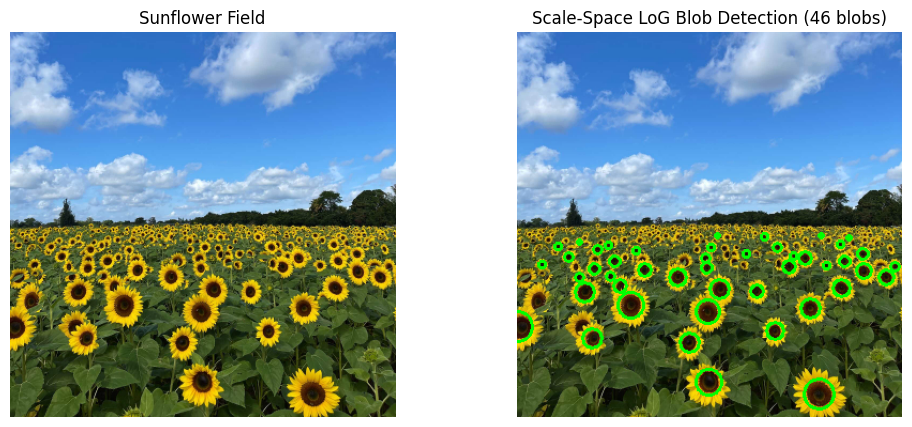

In [23]:
result = cv.cvtColor(im, cv.COLOR_BGR2RGB)

circles.sort(key=lambda c: c["radius"], reverse=True) #Sort circles by radius.

largest_circles = []
for rank, c in enumerate(circles[:10], start=1):
    largest_circles.append({"Rank": rank,"x": c["x"],"y": c["y"],"Sigma": round(c["sigma"], 4),"Radius": c["radius"],"Response": round(c["response"], 6)})
df = pd.DataFrame(largest_circles)
display(df)

for circle in circles:
    center = (circle["x"], circle["y"])
    radius = circle["radius"]
    cv.circle(result,center,radius,(0, 255, 0),2)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(im_rgb)
axes[0].set_title("Sunflower Field")
axes[0].axis('off')
axes[1].imshow(result)
axes[1].set_title(f"Scale-Space LoG Blob Detection ({len(circles)} blobs)")
axes[1].axis('off')

### Blob Detection Using Laplacian of Gaussian (LoG)

The sunflower field image was converted to grayscale and processed using the Laplacian of Gaussian (LoG) method at 100 geometrically spaced scales, ranging from sigma = 0.01 to 11.0 pixels. The squared, scale-normalized LoG response was used to detect blobs. Scale-space extrema were identified using a 3 x 3 x 3 maximum filter with a relative threshold of 0.62. Circles were drawn at the detected blob centres with radius = 2 x sigma.

**Parameters:**

* Sigma range: 0.01 to 11.0 pixels
* Number of scales: 400
* Laplacian kernel size: 1
* Relative threshold: 0.62
* Circle radius: 2 x sigma

**Largest detected circles:**

The largest detected circles have a radius of 14 pixels, with sigma = 7.1956 pixels.

Question 2

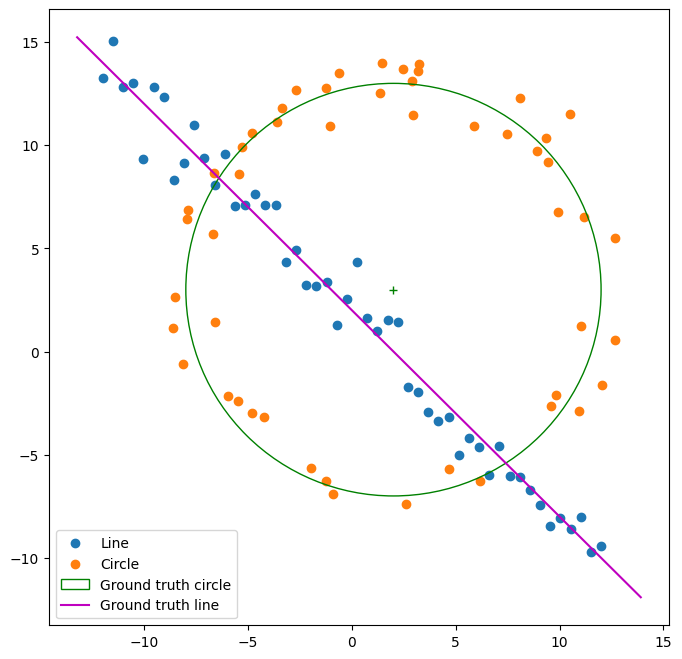

In [16]:
from scipy .optimize import minimize
from scipy import linalg
import matplotlib . pyplot as plt

# np.random.seed(0)
N = 100
half_n = N//2
r = 10
x0_gt , y0_gt = 2, 3 # Center
s = r/16
t = np.random.uniform(0, 2*np.pi , half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n ,1) , y.reshape(half_n ,1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n ,1) , y.reshape(half_n ,1)))
X = np.vstack((X_circ , X_line )) # All points
fig , ax = plt.subplots(1,1, figsize =(8,8))
ax. scatter (X_line [: ,0] , X_line [: ,1] , label= 'Line' )
ax. scatter ( X_circ [: ,0] , X_circ [: ,1] , label= 'Circle' )
circle_gt = plt . Circle ((x0_gt ,y0_gt) , r , color= 'g' , fill=False , label='Ground truth circle' )
ax. add_patch( circle_gt )
ax. plot (( x0_gt) , (y0_gt) , '+' , color= 'g' )
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt . plot (x_ , y_, color= 'm' , label='Ground truth line' )
plt . legend ()

In [25]:
def two_points_lines(p1, p2):
    dir = p2 - p1
    a = dir[1]
    b = -dir[0]
    norm = np.hypot(a, b)
    if norm > 0:
        a /= norm
        b /= norm
        d = a * p1[0] + b * p1[1]
        return np.array([a, b, d])
    else:
        return None

def error(X, model):
    a, b, d = model
    return np.abs(a * X[:, 0] + b * X[:, 1] - d)

def ransac_line(X, iter=2000, threshold=1.5,min_inlier=40, seed=0):
    rng = np.random.default_rng(seed)
    best_model = None
    best_inlier = None

    for _ in range(iter):
        idx = rng.choice(len(X), size=2, replace=False)  # Randomly sample two distinct points
        model = two_points_lines(X[idx[0]], X[idx[1]])
        if model is None:
            continue
        errors = error(X, model)
        inliers = errors < threshold
        if np.sum(inliers) < min_inlier:
            continue    # Reject candidates
        if (best_inlier is None or np.sum(inliers) > np.sum(best_inlier)):
            best_model = model
            best_inlier = inliers

    if best_model is None:
        raise RuntimeError("No valid line found.")
    return best_model, best_inlier

In [26]:
line_model, line_inliers = ransac_line(X)

print("Estimated line [a, b, d]:", line_model)
print("Number of inliers:", np.sum(line_inliers))
print("Normal vector length:",
      np.hypot(line_model[0], line_model[1]))

X_line_inliers = X[line_inliers]
X_remaining = X[~line_inliers]

Estimated line [a, b, d]: [0.73698729 0.67590661 1.64450721]
Number of inliers: 51
Normal vector length: 0.9999999999999999
